# Multi-Query Retrieval: Expanding One Question into Several Searches

A user may express an information need with words that do not appear in the source documents. Multi-query retrieval addresses this by creating several alternate formulations of the same need, retrieving for each formulation, and merging the results. The strategy can improve candidate coverage, but it can also introduce query drift, duplicates, and irrelevant results.

This notebook builds a fully inspectable multi-query pipeline using a small corpus, a simple lexical retriever, and Reciprocal Rank Fusion (RRF). It uses only the Python standard library. Three SVG charts make query coverage, result ranks, and precision/recall trade-offs visible directly in the notebook without requiring a separate plotting package.

## Learning goals

By the end, you should be able to:

- Explain when alternate query formulations help retrieval.
- Distinguish paraphrase-based multi-query retrieval from splitting a question into independent sub-questions.
- Build a deterministic query set and retrieve candidates for each variant.
- Merge result lists with RRF while retaining provenance about which query found each chunk.
- Measure how expansion changes candidate coverage, precision, and recall.
- Recognize query drift, duplicate results, over-expansion, constraints, and reproducibility concerns.
- Interpret custom SVG charts that summarize the experiment.

## 1. Why use multiple queries?

A retriever can only match the evidence its method can represent. A lexical retriever may miss a useful passage if a person asks about “getting back into an account” while the document says “reset your password.” A dense retriever may bridge some vocabulary differences, but can still benefit from targeted reformulations, especially when a question is ambiguous or uses uncommon terminology.

A multi-query pipeline typically:

1. Takes the user's original question as the source of intent.
2. Produces a small set of alternate phrasings or terminology variants.
3. Retrieves a ranked list for each query (often concurrently in production).
4. Merges and deduplicates the lists.
5. Sends a final top-K set to reranking, context construction, or generation.

The goal is usually **higher recall in the candidate pool**, not to pretend that every generated query is independently correct. Always preserve the original query and evaluate whether expansion improves the downstream task.

### Multi-query versus query decomposition

- **Multi-query expansion** rewrites one information need in alternative wording. Variants should remain semantically equivalent to the original.
- **Query decomposition** splits a complex question into distinct sub-questions, each of which may need different evidence.

For example, “How do I reset my password if I lost access to the registered email?” can be searched using alternative formulations of the same need. By contrast, “What is the return window, and how long do refunds take?” contains two answerable parts and may be decomposed. This notebook focuses on alternate formulations; decomposition is covered separately in the roadmap.

### Common sources of alternate queries

- **Paraphrases:** “regain account access” ↔ “sign in again.”
- **Terminology variants:** “password” ↔ “login credentials”; “delivery” ↔ “shipping.”
- **Perspective changes:** phrase the question as a user task, a policy topic, or a named procedure.
- **Explicit expansions:** add a likely synonym or entity spelling while preserving the original meaning.
- **Model-generated rewrites:** use an LLM to propose alternatives, then validate that they preserve intent and constraints.

More queries are not always better. A rewrite that changes the requested entity, time period, negation, or scope is query drift—not a harmless paraphrase.

## 2. A small corpus and one information need

The corpus below includes two useful chunks for the chosen scenario: the normal password-reset procedure and what to do if the registered email is unavailable. It also includes a misleading archived note, related-but-not-answering material, and unrelated content. Stable IDs make deduplication and relevance judgments explicit.

In [2]:
corpus = [
    {'chunk_id': 'C01', 'source': 'account_help', 'topic': 'password_reset',
     'text': 'To reset your password, choose Forgot password on the sign-in page. A reset link is sent to your registered email address.'},
    {'chunk_id': 'C02', 'source': 'account_help', 'topic': 'email_access',
     'text': 'Contact support if you cannot access the email address linked to your account. Support can help verify account ownership.'},
    {'chunk_id': 'C03', 'source': 'account_help', 'topic': 'security',
     'text': 'Turn on two-factor authentication and never share your verification code with anyone.'},
    {'chunk_id': 'C04', 'source': 'account_archive', 'topic': 'legacy',
     'text': 'Archived note: an old password reset flow used a recovery form. This note is not current account guidance.'},
    {'chunk_id': 'C05', 'source': 'shipping_guide', 'topic': 'delivery',
     'text': 'Standard shipping usually takes five to seven business days. Express shipping is available at checkout.'},
    {'chunk_id': 'C06', 'source': 'shopping_policy', 'topic': 'returns',
     'text': 'Unopened products can be returned within thirty days of delivery. Include the order number in your return request.'},
    {'chunk_id': 'C07', 'source': 'shopping_policy', 'topic': 'refunds',
     'text': 'Refunds for eligible orders are returned to the original payment method after the returned item is inspected.'},
    {'chunk_id': 'C08', 'source': 'tenant_handbook', 'topic': 'lease',
     'text': 'The security deposit is due when the lease is signed. The amount is listed in the signed lease agreement.'},
    {'chunk_id': 'C09', 'source': 'cycling_guide', 'topic': 'safety',
     'text': 'Choose a bicycle helmet that fits snugly and sits level on the head. Replace a helmet after a serious impact.'},
    {'chunk_id': 'C10', 'source': 'catalog', 'topic': 'battery',
     'text': 'Model X battery replacement instructions: turn the device off before removing the battery cover.'},
]

original_query = 'How can I access my profile if the contact mailbox is unavailable?'
relevant_ids = {'C01', 'C02'}

print('Original information need:', original_query)
print('Relevant evidence IDs:', sorted(relevant_ids))
print('Corpus size:', len(corpus))

Original information need: How can I access my profile if the contact mailbox is unavailable?
Relevant evidence IDs: ['C01', 'C02']
Corpus size: 10


For this exercise, relevance is judged against the full information need. `C01` gives the reset steps; `C02` covers the special case where the user cannot access the registered email. `C04` mentions password reset, but it is explicitly archived and is not current guidance. This distinction helps reveal why retrieving related words is not the same as retrieving sufficient evidence.

## 3. Establish a single-query baseline

We use a transparent lexical overlap score: the number of distinct query tokens also present in a chunk. This is deliberately simpler than BM25 and embedding retrieval. Here, it isolates the effect of issuing multiple searches and merging their rankings. The same multi-query architecture can wrap BM25, dense search, hybrid retrieval, or a database query.

In [3]:
import re
from collections import defaultdict

STOP_WORDS = {
    'a', 'an', 'and', 'are', 'as', 'at', 'be', 'because', 'but', 'by',
    'can', 'could', 'do', 'for', 'from', 'how', 'i', 'if', 'in', 'is',
    'it', 'my', 'of', 'on', 'or', 'the', 'to', 'we', 'what', 'when',
    'where', 'which', 'who', 'with',
}

def tokenize(text):
    return set(re.findall(r'[a-z0-9]+', text.lower())) - STOP_WORDS

def lexical_score(query, text):
    return len(tokenize(query) & tokenize(text))

def rank_chunks(query, chunks=corpus):
    scored = []
    for chunk in chunks:
        score = lexical_score(query, chunk['text'])
        if score > 0:
            scored.append({**chunk, 'score': score})
    return sorted(scored, key=lambda item: (-item['score'], item['chunk_id']))

baseline_results = rank_chunks(original_query)
for rank, item in enumerate(baseline_results, start=1):
    print(f"{rank}. {item['chunk_id']} score={item['score']} | {item['text']}")

1. C02 score=2 | Contact support if you cannot access the email address linked to your account. Support can help verify account ownership.


A single query often already retrieves some useful evidence. Multi-query retrieval should be justified by a measured gap: a relevant item is missing, under-ranked, or not found reliably on representative queries. It is not useful merely because the system can generate more text.

## 4. Create alternate formulations

For a reproducible experiment, start with hand-written variants that preserve the original intent. Each variant emphasizes different vocabulary:

- A password-reset phrasing for the normal procedure.
- An account/email-access phrasing for the recovery fallback.
- A credentials-recovery paraphrase.

We retain the original query as one of the searches. In production, query variants may be generated by templates, domain synonyms, or an LLM. Generated variants should be checked for meaning, constraints, and unsupported assumptions.

In [4]:
query_variants = {
    'original': original_query,
    'reset_steps': 'forgot password reset sign in instructions registered email',
    'email_fallback': 'cannot access linked account email contact support verify ownership',
    'credentials_paraphrase': 'recover login credentials account access email password',
}

for name, query in query_variants.items():
    print(f'{name:24s} {query}')

original                 How can I access my profile if the contact mailbox is unavailable?
reset_steps              forgot password reset sign in instructions registered email
email_fallback           cannot access linked account email contact support verify ownership
credentials_paraphrase   recover login credentials account access email password


A useful expansion makes alternate relevant evidence retrievable, not just similar wording. Keep the original wording in the set so the system does not lose useful exact terms. If the task contains mandatory constraints (such as a language, date range, tenant, or product), preserve those constraints as structured filters rather than relying on a rewrite not to drop them.

## 5. Retrieve independently and preserve provenance

Each query produces its own ranked list. We keep those lists separately before fusion so we can inspect which formulation found a chunk and at what rank. This provenance is valuable for debugging, evaluation, and explaining the final context to downstream stages.

In [5]:
rankings_by_query = {
    name: rank_chunks(query)
    for name, query in query_variants.items()
}

for name, results in rankings_by_query.items():
    print(f'\n{name}:')
    for rank, item in enumerate(results[:4], start=1):
        print(f"  {rank}. {item['chunk_id']} score={item['score']}")


original:
  1. C02 score=2

reset_steps:
  1. C01 score=6
  2. C04 score=2
  3. C02 score=1
  4. C10 score=1

email_fallback:
  1. C02 score=9
  2. C01 score=1
  3. C04 score=1

credentials_paraphrase:
  1. C02 score=3
  2. C01 score=2
  3. C04 score=2


Notice that one query can find `C01` while another finds `C02`. The result lists also contain overlap: the same chunk can be found by several variants. Multi-query retrieval should merge duplicate chunk IDs rather than sending repeated copies of the same passage downstream.

## 6. Merge results with Reciprocal Rank Fusion

Raw scores from separate query runs should not be summed blindly. Even for the same retriever, a query with more matching words can have a larger score range than a shorter query. Reciprocal Rank Fusion combines positions instead:

`RRF(chunk) = Σ 1 / (c + rank_for_query(chunk))`

Ranks are 1-based. A chunk appearing near the top of several lists accumulates support, and a duplicate ID appears only once in the fused output. The RRF score is a ranking heuristic, not a probability or confidence value. `c` controls how much top positions dominate; we use 60 as a common illustrative setting, not a universal optimum.

In [6]:
def reciprocal_rank_fusion(rankings, c=60, top_n=None):
    if c <= 0:
        raise ValueError('c must be positive')
    scores = defaultdict(float)
    provenance = defaultdict(list)
    records = {}

    for query_name, results in rankings.items():
        selected = results if top_n is None else results[:top_n]
        for rank, item in enumerate(selected, start=1):
            chunk_id = item['chunk_id']
            records[chunk_id] = {key: value for key, value in item.items() if key != 'score'}
            scores[chunk_id] += 1 / (c + rank)
            provenance[chunk_id].append({'query': query_name, 'rank': rank})

    fused = []
    for chunk_id, score in scores.items():
        fused.append({
            **records[chunk_id],
            'rrf_score': score,
            'found_by': provenance[chunk_id],
        })
    return sorted(fused, key=lambda item: (-item['rrf_score'], item['chunk_id']))

multi_query_results = reciprocal_rank_fusion(rankings_by_query, c=60, top_n=5)
for rank, item in enumerate(multi_query_results, start=1):
    sources = ', '.join(f"{hit['query']}@{hit['rank']}" for hit in item['found_by'])
    print(f"{rank}. {item['chunk_id']} RRF={item['rrf_score']:.5f} found by [{sources}]")

1. C02 RRF=0.06505 found by [original@1, reset_steps@3, email_fallback@1, credentials_paraphrase@1]
2. C01 RRF=0.04865 found by [reset_steps@1, email_fallback@2, credentials_paraphrase@2]
3. C04 RRF=0.04788 found by [reset_steps@2, email_fallback@3, credentials_paraphrase@3]
4. C10 RRF=0.01562 found by [reset_steps@4]


The `found_by` field is provenance: it records the query variant and rank that contributed to a chunk's fused score. In production, useful provenance can include retriever name, filter values, index version, and timestamps. Avoid storing sensitive raw query content longer than needed; follow the application's privacy and retention requirements.

### Candidate depth is a separate parameter

`top_n` controls how many results from each query contribute to fusion. It is not the same as final top-K. Shallow per-query depth can omit a useful result before fusion; deep lists can add noise and cost. A practical pipeline measures recall and latency while tuning per-query candidate depth and final context size separately.

In [7]:
for depth in (1, 2, 3, 5):
    fused = reciprocal_rank_fusion(rankings_by_query, c=60, top_n=depth)
    retrieved = {item['chunk_id'] for item in fused}
    recall = len(retrieved & relevant_ids) / len(relevant_ids)
    print(f'per-query depth={depth}: {len(retrieved)} unique candidates, '
          f'relevant found={sorted(retrieved & relevant_ids)}, recall={recall:.2f}')

per-query depth=1: 2 unique candidates, relevant found=['C01', 'C02'], recall=1.00
per-query depth=2: 3 unique candidates, relevant found=['C01', 'C02'], recall=1.00
per-query depth=3: 3 unique candidates, relevant found=['C01', 'C02'], recall=1.00
per-query depth=5: 4 unique candidates, relevant found=['C01', 'C02'], recall=1.00


## 7. Measure retrieval quality

We will use precision@K and recall@K with the same relevance set for the baseline and expanded ranking:

- **Precision@K:** relevant chunks in the first K divided by the number actually returned.
- **Recall@K:** relevant chunks in the first K divided by all known relevant chunks.

For one query and one small synthetic corpus, these metrics are only a teaching example. A real evaluation should contain diverse, independently judged queries and should compare the same candidate budget and filters across systems.

In [8]:
def precision_at_k(results, relevant, k):
    if k <= 0:
        raise ValueError('k must be positive')
    selected = results[:k]
    if not selected:
        return 0.0
    hits = sum(item['chunk_id'] in relevant for item in selected)
    return hits / len(selected)

def recall_at_k(results, relevant, k):
    if k <= 0:
        raise ValueError('k must be positive')
    if not relevant:
        raise ValueError('relevance set must not be empty')
    hits = sum(item['chunk_id'] in relevant for item in results[:k])
    return hits / len(relevant)

baseline_named = [{'chunk_id': item['chunk_id']} for item in baseline_results]
multi_named = [{'chunk_id': item['chunk_id']} for item in multi_query_results]

print(f"{'Method':20s} {'K':>3s} {'Precision':>11s} {'Recall':>8s}")
for method, results in [('single query', baseline_named), ('multi-query RRF', multi_named)]:
    for k in (1, 2, 3, 5):
        print(f'{method:20s} {k:3d} {precision_at_k(results, relevant_ids, k):11.2f} '
              f'{recall_at_k(results, relevant_ids, k):8.2f}')

Method                 K   Precision   Recall
single query           1        1.00     0.50
single query           2        1.00     0.50
single query           3        1.00     0.50
single query           5        1.00     0.50
multi-query RRF        1        1.00     0.50
multi-query RRF        2        1.00     1.00
multi-query RRF        3        0.67     1.00
multi-query RRF        5        0.50     1.00


### Read the metrics together

Multi-query retrieval may find an additional relevant passage at a small candidate depth, improving recall. If it also adds unrelated chunks, precision may fall. When one query asks for evidence with multiple necessary parts, higher recall can be valuable, but only if the final system can distinguish useful evidence from drift and contradictions. Never infer improvement from the number of returned chunks alone.

## 8. Charts: candidate coverage, ranks, and quality curves

The following cells create SVG charts directly from the measured rankings. SVG is vector-based, scales cleanly, and is rendered inline by Jupyter through IPython's display support. No charting package is required. If the notebook is run outside an IPython notebook environment, the cells still generate and validate the SVG and print a note instead of failing.

In [9]:
from html import escape
from xml.etree import ElementTree

try:
    from IPython.display import SVG, display
except ImportError:
    SVG = None
    display = None

def show_svg(svg_text):
    ElementTree.fromstring(svg_text)
    if display is not None and SVG is not None:
        display(SVG(svg_text))
    else:
        print('SVG chart generated and validated. Run in Jupyter to display it inline.')

### Chart 1 — which queries retrieve relevant chunks?

This bar chart shows the number of relevant chunks found in each query's top three results. A variant that finds no relevant chunks may be redundant or poorly phrased; a variant that finds a different relevant chunk expands candidate coverage. The chart measures only this labeled example and should not be generalized beyond it.

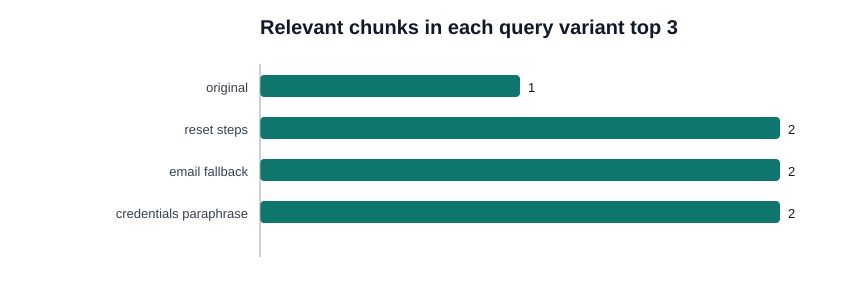

In [10]:
def bar_chart_svg(title, labels, values, max_value, color='#3b82f6', value_suffix=''):
    width = 860
    left = 260
    right = 80
    top = 72
    row_height = 42
    height = top + row_height * len(labels) + 45
    plot_width = width - left - right
    safe_max = max(max_value, 1)
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="#ffffff"/>',
        f'<text x="{left}" y="34" font-family="Arial" font-size="20" font-weight="bold" fill="#111827">{escape(title)}</text>',
    ]
    for index, (label, value) in enumerate(zip(labels, values)):
        y = top + index * row_height
        bar_width = plot_width * value / safe_max
        parts.append(f'<text x="{left - 12}" y="{y + 20}" text-anchor="end" font-family="Arial" font-size="13" fill="#374151">{escape(label)}</text>')
        parts.append(f'<rect x="{left}" y="{y + 3}" width="{bar_width:.1f}" height="22" rx="4" fill="{color}"/>')
        parts.append(f'<text x="{left + bar_width + 8:.1f}" y="{y + 20}" font-family="Arial" font-size="13" fill="#111827">{value}{value_suffix}</text>')
    parts.append(f'<line x1="{left}" y1="{top - 8}" x2="{left}" y2="{height - 28}" stroke="#9ca3af"/>')
    parts.append('</svg>')
    return ''.join(parts)

coverage_labels = []
coverage_values = []
for name, results in rankings_by_query.items():
    coverage_labels.append(name.replace('_', ' '))
    coverage_values.append(sum(item['chunk_id'] in relevant_ids for item in results[:3]))

show_svg(bar_chart_svg(
    'Relevant chunks in each query variant top 3',
    coverage_labels,
    coverage_values,
    max_value=len(relevant_ids),
    color='#0f766e',
))

Read the result together with the individual ranked lists. A variant can be useful even if it retrieves only one of several relevant passages, provided it retrieves evidence other variants miss. Conversely, a variant may repeatedly retrieve only the same passages and add cost without improving coverage.

### Chart 2 — rank position by query

This rank matrix shows where selected chunks appear for each query. A blank cell means the chunk did not appear in that query's result list. Lower ranks (1, 2, ...) are stronger positions. The two relevant chunks are marked with a green background; the archived distractor is marked in amber.

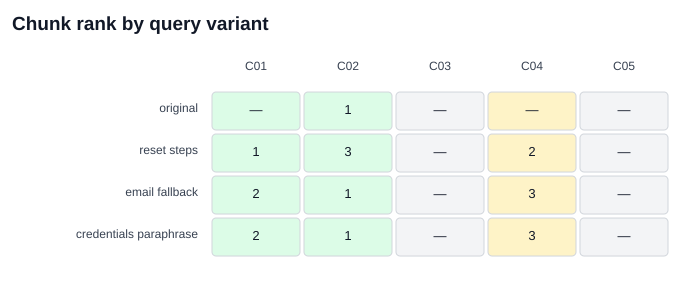

In [11]:
def rank_matrix_svg(rankings, chunk_ids, relevant):
    cell_w = 92
    label_w = 210
    top = 90
    row_h = 42
    width = label_w + cell_w * len(chunk_ids) + 30
    height = top + row_h * len(rankings) + 25
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="#ffffff"/>',
        '<text x="12" y="30" font-family="Arial" font-size="19" font-weight="bold" fill="#111827">Chunk rank by query variant</text>',
    ]
    for col, chunk_id in enumerate(chunk_ids):
        x = label_w + col * cell_w
        parts.append(f'<text x="{x + cell_w / 2}" y="70" text-anchor="middle" font-family="Arial" font-size="12" fill="#374151">{escape(chunk_id)}</text>')
    for row, (name, results) in enumerate(rankings.items()):
        y = top + row * row_h
        parts.append(f'<text x="{label_w - 12}" y="{y + 22}" text-anchor="end" font-family="Arial" font-size="12" fill="#374151">{escape(name.replace("_", " "))}</text>')
        ranks = {item['chunk_id']: rank for rank, item in enumerate(results, start=1)}
        for col, chunk_id in enumerate(chunk_ids):
            x = label_w + col * cell_w
            fill = '#dcfce7' if chunk_id in relevant else ('#fef3c7' if chunk_id == 'C04' else '#f3f4f6')
            rank_text = str(ranks[chunk_id]) if chunk_id in ranks else '—'
            parts.append(f'<rect x="{x + 2}" y="{y + 2}" width="{cell_w - 4}" height="{row_h - 4}" rx="4" fill="{fill}" stroke="#d1d5db"/>')
            parts.append(f'<text x="{x + cell_w / 2}" y="{y + 24}" text-anchor="middle" font-family="Arial" font-size="13" fill="#111827">{rank_text}</text>')
    parts.append('</svg>')
    return ''.join(parts)

show_svg(rank_matrix_svg(rankings_by_query, ['C01', 'C02', 'C03', 'C04', 'C05'], relevant_ids))

The rank matrix reveals both complementarity and overlap. If all variants return the same chunks in nearly the same order, expansion may not help. If a relevant chunk appears only for one formulation, that query may be adding coverage. An irrelevant chunk appearing at rank 1 repeatedly may indicate a scoring weakness that fusion will not fix automatically.

### Chart 3 — precision and recall as final K increases

The line chart compares precision@K and recall@K for the single-query ranking and the fused multi-query ranking. Recall is non-decreasing as K grows; precision can rise or fall depending on the relevance of newly included chunks. The values come from this synthetic example, and the chart intentionally plots both metrics because optimizing only one can hide a trade-off.

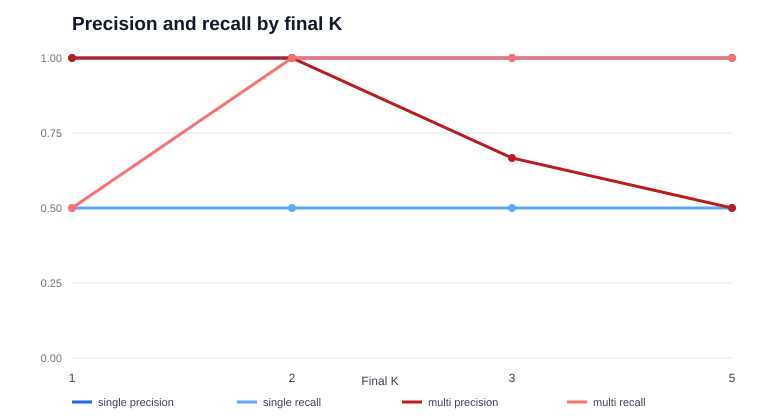

In [12]:
def quality_chart_svg(series, ks):
    width, height = 760, 420
    left, right, top, bottom = 72, 28, 58, 62
    plot_w = width - left - right
    plot_h = height - top - bottom
    colors = {'single precision': '#2563eb', 'single recall': '#60a5fa',
              'multi precision': '#b91c1c', 'multi recall': '#f87171'}
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="#ffffff"/>',
        f'<text x="{left}" y="30" font-family="Arial" font-size="19" font-weight="bold" fill="#111827">Precision and recall by final K</text>',
    ]
    for tick in (0, 0.25, 0.5, 0.75, 1):
        y = top + plot_h * (1 - tick)
        parts.append(f'<line x1="{left}" y1="{y:.1f}" x2="{width - right}" y2="{y:.1f}" stroke="#e5e7eb"/>')
        parts.append(f'<text x="{left - 10}" y="{y + 4:.1f}" text-anchor="end" font-family="Arial" font-size="11" fill="#6b7280">{tick:.2f}</text>')
    x_positions = [left + (index / max(len(ks) - 1, 1)) * plot_w for index in range(len(ks))]
    for x, k in zip(x_positions, ks):
        parts.append(f'<text x="{x:.1f}" y="{height - bottom + 24}" text-anchor="middle" font-family="Arial" font-size="12" fill="#374151">{k}</text>')
    for name, values in series.items():
        points = []
        for x, value in zip(x_positions, values):
            y = top + plot_h * (1 - value)
            points.append((x, y))
        point_string = ' '.join(f'{x:.1f},{y:.1f}' for x, y in points)
        color = colors[name]
        parts.append(f'<polyline points="{point_string}" fill="none" stroke="{color}" stroke-width="3"/>')
        for x, y in points:
            parts.append(f'<circle cx="{x:.1f}" cy="{y:.1f}" r="4" fill="{color}"/>')
    legend_items = list(series.items())
    for index, (name, _) in enumerate(legend_items):
        x = left + index * 165
        parts.append(f'<line x1="{x}" y1="{height - 18}" x2="{x + 20}" y2="{height - 18}" stroke="{colors[name]}" stroke-width="3"/>')
        parts.append(f'<text x="{x + 26}" y="{height - 14}" font-family="Arial" font-size="11" fill="#374151">{escape(name)}</text>')
    parts.append(f'<text x="{width / 2}" y="{height - 35}" text-anchor="middle" font-family="Arial" font-size="12" fill="#374151">Final K</text>')
    parts.append('</svg>')
    return ''.join(parts)

ks = [1, 2, 3, 5]
quality_series = {
    'single precision': [precision_at_k(baseline_named, relevant_ids, k) for k in ks],
    'single recall': [recall_at_k(baseline_named, relevant_ids, k) for k in ks],
    'multi precision': [precision_at_k(multi_named, relevant_ids, k) for k in ks],
    'multi recall': [recall_at_k(multi_named, relevant_ids, k) for k in ks],
}
show_svg(quality_chart_svg(quality_series, ks))

The chart is a diagnostic, not a universal performance claim. A ranking can achieve perfect recall at larger K simply by returning more candidates; the additional context may increase cost or confuse answer generation. Compare systems at practical K values and evaluate whether the final answer is correct and grounded.

## 9. Query drift: when expansion makes things worse

A rewrite can drift from the user's actual intent. For example, turning a password-reset question into “account security verification codes” may retrieve multi-factor authentication instructions that are related to accounts but do not answer how to regain access. A query generator can introduce:

- A different entity, product, or document version.
- A broader or narrower time period than requested.
- Unsupported assumptions about cause or user intent.
- Loss of negation or a critical condition.
- Related-topic terms that overwhelm the original query.

The next variant is intentionally a drift example. We do not include it in the default fusion ranking. Compare its results and observe how adding it changes the candidate pool.

In [ ]:
drift_query = 'account security two factor verification code reset'
drift_results = rank_chunks(drift_query)
print('Drift query:', drift_query)
for rank, item in enumerate(drift_results[:5], start=1):
    print(f"{rank}. {item['chunk_id']} score={item['score']} topic={item['topic']}")

rankings_with_drift = {**rankings_by_query, 'drifted_security': drift_results}
drift_fused = reciprocal_rank_fusion(rankings_with_drift, c=60, top_n=3)
print('\nTop 6 after adding drifted query:', [item['chunk_id'] for item in drift_fused[:6]])

The drifted query may promote `C03` because it contains security and verification-code terms. That passage is related but is not among the labeled evidence for the user's particular question. In a production system, constrain the rewrite prompt or template, preserve the original, reject variants that change entities or conditions, and inspect retrieval metrics per query category.

## 10. Practical design choices

### How many variants?

Use the smallest number that measurably improves candidate recall or answer quality. More variants mean more retrieval calls, more duplicates, and more opportunities for drift. A few diverse alternatives often provide more value than many near-identical rewrites.

### How should results be merged?

- **Union:** retain any unique candidate from any query. Simple and recall-oriented, but has no ranking signal by itself.
- **Maximum score:** keep the best score per chunk. This avoids rewarding repetition, but raw score comparability across queries may still be weak.
- **RRF:** combine ranks and reward candidates appearing near the top across queries. It avoids direct score-scale comparison but repeated discovery across many similar queries can still influence ranks.
- **Learned fusion or reranking:** use a labeled model or cross-encoder when the application can support the data, latency, and evaluation requirements.

### Keep constraints outside the rewrite

Mandatory metadata constraints—such as tenant, access scope, date range, or selected product—should be applied consistently to every expanded query. Do not rely on generated text to preserve authorization or filter semantics. This continues the principle from metadata-filtered retrieval: filters define eligible candidates independently of wording.

## 11. Evaluation protocol for real systems

A useful multi-query experiment should:

1. Build a representative set of original user questions, including paraphrases, ambiguous questions, rare terms, and no-answer cases.
2. Create relevance judgments for each original information need; do not label each generated rewrite as a new user task unless its meaning truly differs.
3. Compare single-query and multi-query retrieval with the same corpus, filters, candidate budget, and final K.
4. Report recall@K and precision@K; add ranking-sensitive metrics such as MRR or nDCG when appropriate.
5. Measure latency, number of retrieval calls, unique candidate count, and answer-level grounding.
6. Inspect failures by category: useful evidence missed, irrelevant drift, contradictory passages, duplicates, and missing corpus evidence.
7. Keep a held-out query set when tuning the number of variants, prompt, candidate depth, or fusion weights.

A higher recall@K does not alone prove the system is better. The added candidates must be relevant and usable by the downstream stage.

## 12. Exercises

1. Write two alternate queries for the same information need that emphasize different vocabulary but do not change the requested outcome.
2. Add one query that retrieves `C02` and one that retrieves `C01`. Use the provenance field to show which variant contributed each result.
3. Change per-query depth from 1 to 5. How do unique candidate count, recall, and precision change?
4. Create a drifted variant that changes an important condition (for example, asks for current policy but emphasizes archived instructions). How does it change the fused ranking?
5. Compare simple union with RRF. Which is better for candidate coverage? Which provides an ordering?
6. Make the original question include a mandatory date or product constraint. Show how you would apply the same structured filter to every query variant.
7. Create relevance judgments for five original questions and build an aggregate chart comparing single-query and multi-query recall@K.
8. If an LLM generates variants, what checks would you use to detect lost negation, changed entities, or unsupported assumptions?

### Optional extension: check retrieval and fusion invariants

These checks verify deterministic ranking, deduplication by chunk ID, positive relevance recall, and rejection of an invalid RRF constant.

In [ ]:
assert len({item['chunk_id'] for item in multi_query_results}) == len(multi_query_results)
assert recall_at_k(multi_named, relevant_ids, 5) > 0
assert rank_chunks(original_query) == rank_chunks(original_query)

try:
    reciprocal_rank_fusion(rankings_by_query, c=0)
except ValueError:
    print('Invalid RRF constant rejected as expected.')
else:
    raise AssertionError('c=0 should have raised ValueError')

print('Ranking, fusion, deduplication, and evaluation checks passed.')

## Summary

Multi-query retrieval searches several alternate formulations of one information need, then merges and deduplicates the results. It can improve candidate coverage when wording differs, but query drift can add irrelevant or misleading passages. Preserve the original query, keep provenance, apply mandatory filters consistently, and use a merge strategy such as RRF when raw score scales are not comparable.

Evaluate the approach on judged original questions with matched candidate budgets. Use precision and recall together, inspect charts and passages, and measure latency and downstream answer quality. Multi-query expansion is most useful when it addresses a demonstrated vocabulary or retrieval gap; more queries are not automatically better. The next notebook covers **query decomposition**, where a complex question is split into distinct sub-questions rather than paraphrased.